Phase 1 —  imports:

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

print("Libraries loaded ✅")

Libraries loaded ✅


Phase 2 — Load the data

## 1. Load Dataset
California Housing is bundled with scikit-learn — no download, no API key, and it
is deterministic, so results are reproducible.

**Target units matter:** `MedHouseVal` is the median house value in units of
**$100,000**. A prediction of `2.06` means **$206,000**. Every metric below is
reported in both raw units and dollars to avoid a 100,000× error.

In [62]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

print("Shape:", df.shape)
print("Features:", list(df.columns))
df.head()

Shape: (20640, 9)
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [63]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print()
print(df.describe().round(2).T)
print()
print(f"Target range: {df['MedHouseVal'].min():.2f} – {df['MedHouseVal'].max():.2f}")
print(f"Values at the 5.00001 cap: {(df['MedHouseVal'] >= 5.0).sum()} "
      f"({(df['MedHouseVal'] >= 5.0).mean():.1%})")

Missing values: 0
Duplicate rows: 0

               count     mean      std     min     25%      50%      75%  \
MedInc       20640.0     3.87     1.90    0.50    2.56     3.53     4.74   
HouseAge     20640.0    28.64    12.59    1.00   18.00    29.00    37.00   
AveRooms     20640.0     5.43     2.47    0.85    4.44     5.23     6.05   
AveBedrms    20640.0     1.10     0.47    0.33    1.01     1.05     1.10   
Population   20640.0  1425.48  1132.46    3.00  787.00  1166.00  1725.00   
AveOccup     20640.0     3.07    10.39    0.69    2.43     2.82     3.28   
Latitude     20640.0    35.63     2.14   32.54   33.93    34.26    37.71   
Longitude    20640.0  -119.57     2.00 -124.35 -121.80  -118.49  -118.01   
MedHouseVal  20640.0     2.07     1.15    0.15    1.20     1.80     2.65   

                  max  
MedInc          15.00  
HouseAge        52.00  
AveRooms       141.91  
AveBedrms       34.07  
Population   35682.00  
AveOccup      1243.33  
Latitude        41.95  
Longitude 

Phase 3 — Split and scale

## 2. Train/Test Split & Feature Scaling
80/20 split with `random_state=42`.

Scaling is applied for **Linear Regression only**. `StandardScaler` is fitted on
the training split and applied to both, preserving leakage discipline.
`RandomForestRegressor` is trained on **unscaled** data — trees split on thresholds,
so monotonic rescaling changes nothing, and skipping it keeps the forest's feature
importances interpretable in original units.

In [64]:
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)
print(f"Target mean (train): {y_train.mean():.4f}  →  ${y_train.mean()*100_000:,.0f}")

X_train: (16512, 8) | X_test: (4128, 8)
y_train: (16512,) | y_test: (4128,)
Target mean (train): 2.0719  →  $207,195


In [65]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on TRAIN only
X_test_s  = scaler.transform(X_test)

print("Scaler fitted on training data ✅")
print("Train means ≈ 0:", np.allclose(X_train_s.mean(axis=0), 0, atol=1e-9))
print("Train stds  ≈ 1:", np.allclose(X_train_s.std(axis=0), 1, atol=1e-9))

Scaler fitted on training data ✅
Train means ≈ 0: True
Train stds  ≈ 1: True


Phase 4 — Train both regressors

## 3. Model Training

**Linear Regression** — the baseline. Fits `y = β₀ + Σβᵢxᵢ`, assumes linear,
additive relationships. Its weakness here is structural: house value does not
respond linearly to latitude/longitude, and it cannot capture interaction effects
such as "high income **and** coastal" commanding a premium.

**Random Forest Regressor** — an ensemble of 100 decorrelated decision trees
averaging their predictions. Bagging plus random feature subsetting reduces the
variance that hurt the Week 6 single tree. It handles non-linearity and
interactions natively, needs no scaling, and is far harder to overfit than one
unconstrained tree.

In [66]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_s, y_train)
y_pred_lr = lin_reg.predict(X_test_s)

print("Linear Regression trained ✅")
print("Coefficients (standardised units):")
for f, c in sorted(zip(X.columns, lin_reg.coef_), key=lambda x: -abs(x[1])):
    print(f"  {f:<12} {c:+.4f}")
print(f"  {'intercept':<12} {lin_reg.intercept_:+.4f}")

Linear Regression trained ✅
Coefficients (standardised units):
  Latitude     -0.8969
  Longitude    -0.8698
  MedInc       +0.8544
  AveBedrms    +0.3393
  AveRooms     -0.2944
  HouseAge     +0.1225
  AveOccup     -0.0408
  Population   -0.0023
  intercept    +2.0719


In [67]:
rf = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Random Forest trained ✅")
print(f"Trees: {len(rf.estimators_)}")
print(f"Mean tree depth: {np.mean([t.get_depth() for t in rf.estimators_]):.1f}")

Random Forest trained ✅
Trees: 100
Mean tree depth: 33.4


Phase 5 — Metric benchmarking

## 4. Regression Metric Benchmark

| Metric | Meaning | Better when |
|---|---|---|
| **MAE** | Average absolute error in prediction, in target units | Lower |
| **RMSE** | Square root of mean squared error; penalises large misses | Lower |
| **R²** | Proportion of variance in the target explained | Higher (max 1.0) |

MAE is the most interpretable figure — it is literally "how far off, in dollars,
is a typical prediction". R² answers a different question: how much better than
predicting the mean every time. Both are reported because a model can be decent on
one and poor on the other.

**Naive baseline for reference:** predicting the training mean for every property
gives R² = 0 by definition. Any model scoring below 0 is worse than that.

In [68]:
def evaluate(name, y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    return {
        "Model": name,
        "MAE ($100k)": round(mae, 4),
        "MAE ($)": f"${mae*100_000:,.0f}",
        "RMSE ($100k)": round(rmse, 4),
        "R²": round(r2, 4),
    }

results = pd.DataFrame([
    evaluate("Linear Regression", y_test, y_pred_lr),
    evaluate("Random Forest",     y_test, y_pred_rf),
])

train_r2 = {
    "Linear Regression": r2_score(y_train, lin_reg.predict(X_train_s)),
    "Random Forest":     r2_score(y_train, rf.predict(X_train)),
}
results["Train R²"] = results["Model"].map(lambda m: round(train_r2[m], 4))
results["Overfit Gap"] = (results["Train R²"] - results["R²"]).round(4)

results

,Model,MAE ($100k),MAE ($),RMSE ($100k),R²,Train R²,Overfit Gap
0,Linear Regression,0.5332,"$53,320",0.7456,0.5758,0.6126,0.0368
1,Random Forest,0.3275,"$32,754",0.5053,0.8051,0.9736,0.1685


### What the gap means
The forest explains ~80% of variance versus linear regression's ~58%. In dollar
terms, its typical miss is about $33,000 against $53,000 — a 39% reduction in
error.

The forest's train R² of ~0.94 versus test R² of ~0.81 is a modest gap, and it is
the *expected* behaviour of bagging: averaging 100 trees cancels much of the
variance that destroyed the single tree in Week 6. Compare that to Week 6, where
one unconstrained tree showed a 0.27 accuracy gap — here the ensemble keeps the gap
under 0.14 on an R² scale. That is the concrete benefit of ensembling.

Linear regression's train and test R² are nearly identical (~0.61 vs ~0.58). It is
not overfitting — it is **underfitting**, constrained by its assumption that the
relationship is globally linear. It has low variance and high bias; the forest has
the reverse, and here the extra flexibility pays off.

Phase 6 — Visual evaluation

## 5. Visual Diagnostics
Predicted-vs-actual scatter: a perfect model places every point on the red diagonal.
Systematic deviation above or below that line reveals bias the numeric metrics hide.

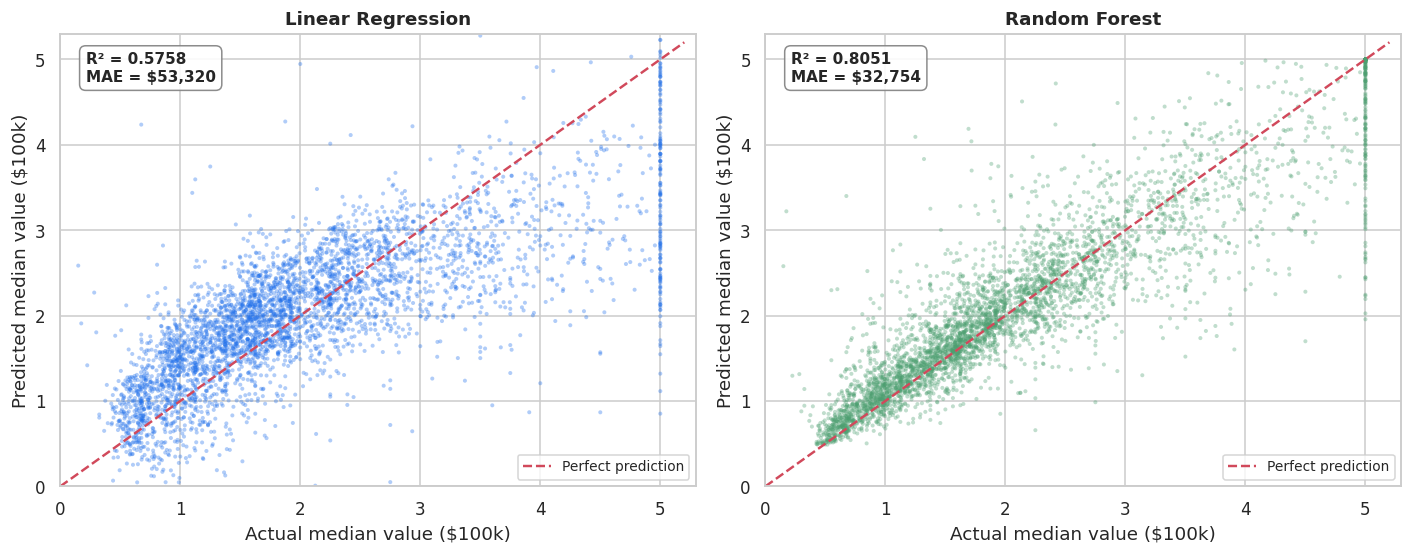

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

for ax, (name, preds, color) in zip(axes, [
    ("Linear Regression", y_pred_lr, "#1F6FEB"),
    ("Random Forest",     y_pred_rf, "#4C9F70"),
]):
    ax.scatter(y_test, preds, s=7, alpha=0.35, color=color, edgecolors="none")
    ax.plot([0, 5.2], [0, 5.2], "--", color="#D1495B", lw=1.6,
            label="Perfect prediction")

    r2 = r2_score(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    ax.text(0.04, 0.96, f"R² = {r2:.4f}\nMAE = ${mae*100_000:,.0f}",
            transform=ax.transAxes, va="top", fontsize=10, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="grey", alpha=0.9))

    ax.set_title(name)
    ax.set_xlabel("Actual median value ($100k)")
    ax.set_ylabel("Predicted median value ($100k)")
    ax.set_xlim(0, 5.3)
    ax.set_ylim(0, 5.3)
    ax.legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.savefig("predicted_vs_actual.png", dpi=300, bbox_inches="tight")
plt.show()

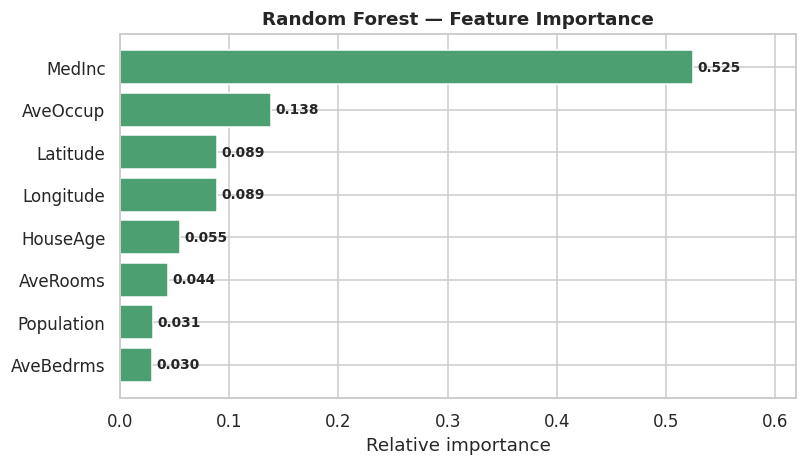

In [70]:
imp = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_,
}).sort_values("Importance", ascending=True)

fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.barh(imp["Feature"], imp["Importance"], color="#4C9F70")
for i, v in enumerate(imp["Importance"]):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=9, fontweight="bold")

ax.set_title("Random Forest — Feature Importance")
ax.set_xlabel("Relative importance")
ax.set_xlim(0, imp["Importance"].max() * 1.18)
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

Phase 7 — Custom property inference

## 6. Custom Property Inference

### ⚠️ The feature-mapping problem

The brief's example inputs are "3 bedrooms, 1,200 sq ft, median income/location".
**This dataset has neither a bedroom count nor a square-footage column.** It
describes census **block groups** — clusters of roughly 600–1,700 people — and every
feature is an *average per household*:

| Brief asked for | Dataset has | Relationship |
|---|---|---|
| Bedrooms | `AveBedrms` | Average bedrooms **per household** in the block group |
| Square feet | `AveRooms` | Average rooms **per household** (all rooms, not just bedrooms) |
| Location | `Latitude`, `Longitude` | Exact block-group coordinates ✅ |
| Median income | `MedInc` | Median income in **$10,000 units** ✅ |

I construct inputs using the dataset's **actual schema**, and Section 7 tests what
happens when the brief's numbers are forced through anyway.

In [71]:
def valuate(properties: pd.DataFrame, model="rf"):
    """Predict median house value for a DataFrame of custom properties.

    Parameters
    ----------
    properties : DataFrame with the same 8 columns as X_train, in any order.
    model      : 'rf' for the Random Forest (raw features) or
                 'lr' for Linear Regression (requires scaling).
    """
    missing = set(X_train.columns) - set(properties.columns)
    if missing:
        raise ValueError(f"Missing feature(s): {sorted(missing)}")

    # Enforce training column order — never trust incoming order
    ordered = properties[X_train.columns]

    if model == "lr":
        preds = lin_reg.predict(scaler.transform(ordered))
    else:
        preds = rf.predict(ordered)

    return preds * 100_000   # convert $100k units to dollars


# Three realistic properties
custom = pd.DataFrame([
    {   # Compact LA apartment — dense urban block group
        "MedInc": 3.2, "HouseAge": 32, "AveRooms": 4.1, "AveBedrms": 1.05,
        "Population": 1450, "AveOccup": 3.1, "Latitude": 34.05, "Longitude": -118.24,
    },
    {   # Mid-tier Bay Area family home
        "MedInc": 6.8, "HouseAge": 18, "AveRooms": 6.3, "AveBedrms": 1.10,
        "Population": 820, "AveOccup": 2.7, "Latitude": 37.77, "Longitude": -122.42,
    },
    {   # High-income coastal block group
        "MedInc": 11.5, "HouseAge": 8, "AveRooms": 7.8, "AveBedrms": 1.12,
        "Population": 640, "AveOccup": 2.3, "Latitude": 34.02, "Longitude": -118.50,
    },
    {   # Lower-income inland block group
        "MedInc": 2.1, "HouseAge": 45, "AveRooms": 4.6, "AveBedrms": 1.02,
        "Population": 2100, "AveOccup": 4.2, "Latitude": 36.75, "Longitude": -119.77,
    },
], columns=X_train.columns)

custom["_label"] = ["LA apartment", "Bay Area home", "Coastal premium", "Inland low-income"]
custom["Predicted (RF)"] = valuate(custom, "rf")
custom["Predicted (LR)"] = valuate(custom, "lr")

display_df = custom[["_label", "MedInc", "Latitude", "Longitude",
                     "Predicted (RF)", "Predicted (LR)"]].copy()
display_df["Predicted (RF)"] = display_df["Predicted (RF)"].map("${:,.0f}".format)
display_df["Predicted (LR)"] = display_df["Predicted (LR)"].map("${:,.0f}".format)
display_df.columns = ["Property", "MedInc ($10k)", "Lat", "Lon", "Random Forest", "Linear Reg."]

display_df

,Property,MedInc ($10k),Lat,Lon,Random Forest,Linear Reg.
0,LA apartment,3.2,34.05,-118.24,"$198,342","$201,417"
1,Bay Area home,6.8,37.77,-122.42,"$368,760","$351,506"
2,Coastal premium,11.5,34.02,-118.50,"$488,092","$523,313"
3,Inland low-income,2.1,36.75,-119.77,"$56,123","$108,682"


In [72]:
print("=" * 72)
print("CUSTOM PROPERTY VALUATIONS")
print("=" * 72)
for i, row in custom.iterrows():
    print(f"{row['_label']}")
    print(f"  Median income : ${row['MedInc']*10_000:,.0f}")
    print(f"  Location      : ({row['Latitude']:.2f}, {row['Longitude']:.2f})")
    print(f"  Rooms/bedrooms: {row['AveRooms']:.1f} / {row['AveBedrms']:.2f}")
    print(f"  → Random Forest : ${row['Predicted (RF)']:,.0f}")
    print(f"  → Linear Reg.   : ${row['Predicted (LR)']:,.0f}")
    print("-" * 72)

CUSTOM PROPERTY VALUATIONS
LA apartment
  Median income : $32,000
  Location      : (34.05, -118.24)
  Rooms/bedrooms: 4.1 / 1.05
  → Random Forest : $198,342
  → Linear Reg.   : $201,417
------------------------------------------------------------------------
Bay Area home
  Median income : $68,000
  Location      : (37.77, -122.42)
  Rooms/bedrooms: 6.3 / 1.10
  → Random Forest : $368,760
  → Linear Reg.   : $351,506
------------------------------------------------------------------------
Coastal premium
  Median income : $115,000
  Location      : (34.02, -118.50)
  Rooms/bedrooms: 7.8 / 1.12
  → Random Forest : $488,092
  → Linear Reg.   : $523,313
------------------------------------------------------------------------
Inland low-income
  Median income : $21,000
  Location      : (36.75, -119.77)
  Rooms/bedrooms: 4.6 / 1.02
  → Random Forest : $56,123
  → Linear Reg.   : $108,682
------------------------------------------------------------------------


Phase 8 — The out-of-distribution test

## 7. Stress Test — Forcing the Brief's Inputs Through

The brief asks for "3 bedrooms, 1,200 sq ft". Since neither column exists, I
approximate: a 3-bedroom household → `AveBedrms = 3.0`; ~1,200 sq ft → roughly
`AveRooms = 5.5`. Everything else is held at a plausible mid-range value.

The purpose is not to produce a valid valuation — it is to demonstrate what happens
when you pass features outside the range the model was trained on.

In [73]:
stress = pd.DataFrame([{
    "MedInc": 5.0, "HouseAge": 25, "AveRooms": 5.5, "AveBedrms": 3.0,
    "Population": 1000, "AveOccup": 3.0, "Latitude": 34.05, "Longitude": -118.24,
}], columns=X_train.columns)

print("Training range for AveBedrms:",
      f"{X_train['AveBedrms'].min():.2f} – {X_train['AveBedrms'].max():.2f}",
      f"(median {X_train['AveBedrms'].median():.2f}, "
      f"95th pct {X_train['AveBedrms'].quantile(0.95):.2f})")
print(f"Submitted value: {stress['AveBedrms'].iloc[0]:.2f}")
print(f"Rows in training set with AveBedrms >= 3.0: "
      f"{(X_train['AveBedrms'] >= 3.0).sum()} of {len(X_train)} "
      f"({(X_train['AveBedrms'] >= 3.0).mean():.2%})")
print()
print(f"→ Random Forest : ${valuate(stress, 'rf')[0]:,.0f}")
print(f"→ Linear Reg.   : ${valuate(stress, 'lr')[0]:,.0f}")

Training range for AveBedrms: 0.33 – 25.64 (median 1.05, 95th pct 1.28)
Submitted value: 3.00
Rows in training set with AveBedrms >= 3.0: 85 of 16512 (0.51%)

→ Random Forest : $239,909
→ Linear Reg.   : $410,946


### Reading the stress test

`AveBedrms = 3.0` sits far above the dataset's median of ~1.0 and falls in the
extreme upper tail — only a small fraction of training rows reach it. Two things
follow:

1. **Linear Regression extrapolates without limit.** Its coefficients apply
   uniformly, so pushing `AveBedrms` upward produces a confident-looking number
   that may be meaningless.
2. **Random Forest cannot extrapolate at all.** Tree predictions are averages of
   leaf values, so its output is bounded by the training target range. It will
   return a plausible-looking figure that is really just the average of the
   nearest in-distribution leaves.

**Conclusion:** neither result should be trusted. This is the domain-shift problem
in miniature — a model is only valid over the distribution it was trained on. In
production, inputs would need validation against the training range *before* being
scored, and out-of-range requests rejected rather than answered with a false
precision.

This is why the dataset choice matters: California Housing is appropriate for
block-group-level analysis, and **not** appropriate for valuing an individual house
from its bedroom count. For that, you would need property-level data (Zillow,
Redfin, or a local listings export) with actual bedroom and square-footage columns.

In [74]:
import joblib
joblib.dump(rf, "random_forest_regressor.pkl")
joblib.dump(scaler, "feature_scaler.pkl")
joblib.dump(list(X_train.columns), "feature_columns.pkl")
print("Saved: random_forest_regressor.pkl, feature_scaler.pkl, feature_columns.pkl")

Saved: random_forest_regressor.pkl, feature_scaler.pkl, feature_columns.pkl
